In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
x_train = np.load("train_xs.npz")["train_xs"]
y_train_dict = np.load("train_ys.npz")
y_train = y_train_dict["train_ys"]
y_train_is_snow = y_train_dict["train_is_snow"]
y_train_is_cloud = y_train_dict["train_is_cloud"]

x_train = np.transpose(x_train, (0, 2, 3, 1))
print(x_train.shape, y_train.shape, y_train_is_snow.shape, y_train_is_cloud.shape)

(1800, 60, 60, 3) (1800,) (1800,) (1800,)


# Bins for snow and cloud

In [20]:
cloud_idx = np.where(y_train_is_cloud == 1)[0]
print(f"Fraction of cloud: {100* len(cloud_idx) / len(y_train)}%")

snow_idx = np.where(y_train_is_snow == 1)[0]
print(f"Fraction of snow: {100*len(snow_idx) / len(y_train)}%")

snow_and_cloud_idx = np.intersect1d(snow_idx, cloud_idx)
print(f"Fraction of snow and cloud: {100*len(snow_and_cloud_idx) / len(y_train)}%")


Fraction of cloud: 3.3333333333333335%
Fraction of snow: 8.88888888888889%
Fraction of snow and cloud: 0.0%


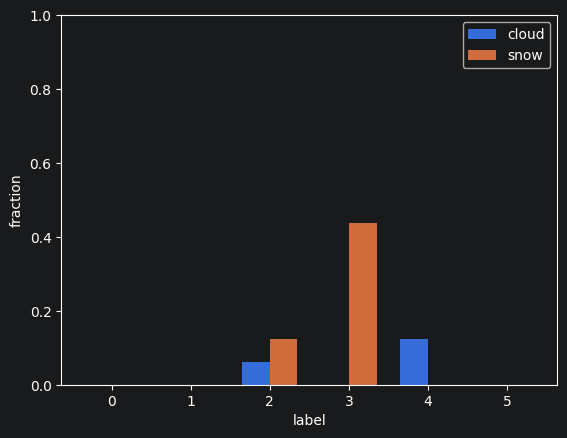

In [21]:
import numpy as np
import matplotlib.pyplot as plt

cloud_fractions, snow_fractions = [], []

for label in range(6):
    idxs = np.where(y_train == label)[0][:16]
    cloud_fractions.append(len(np.intersect1d(idxs, cloud_idx)) / len(idxs))
    snow_fractions.append(len(np.intersect1d(idxs, snow_idx)) / len(idxs))

x = np.arange(6)      # one position per label
width = 0.35          # bar width

fig, ax = plt.subplots()
ax.bar(x - width/2, cloud_fractions, width, label="cloud")
ax.bar(x + width/2, snow_fractions, width, label="snow")

ax.set_xticks(x)
ax.set_xticklabels([str(l) for l in range(6)])  # or your class names
ax.set_xlabel("label")
ax.set_ylabel("fraction")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

LABEL:  0


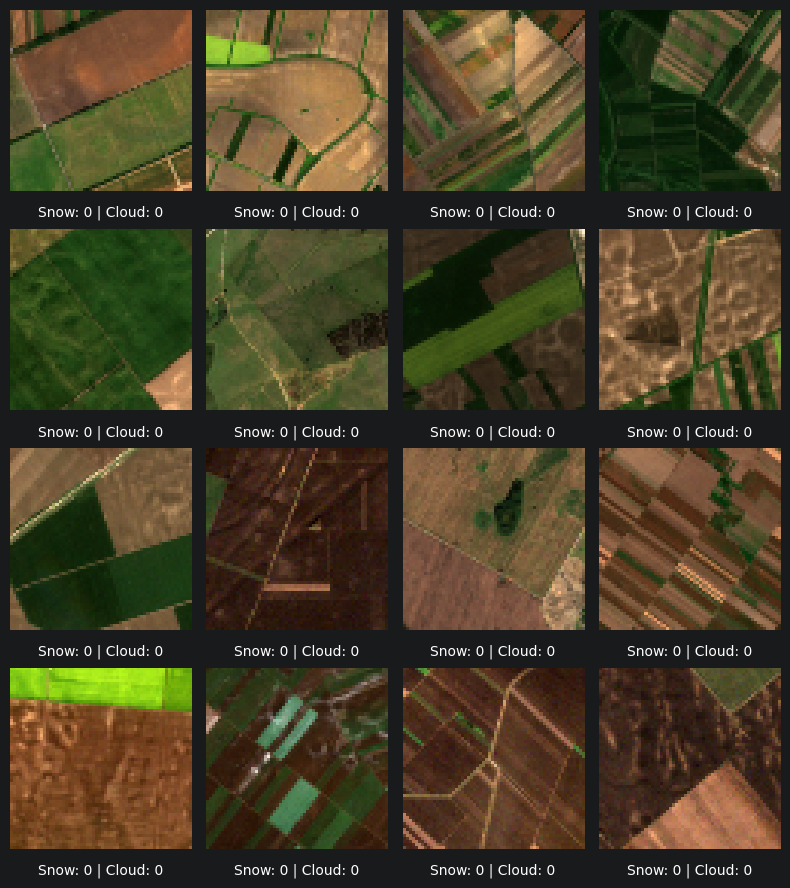

LABEL:  1


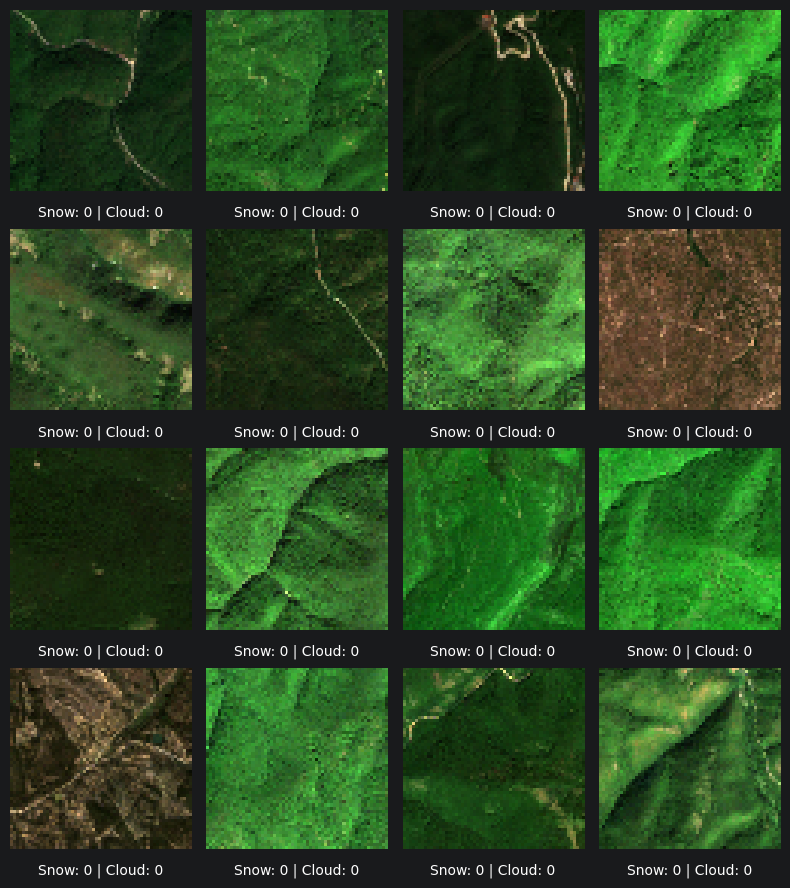

LABEL:  2


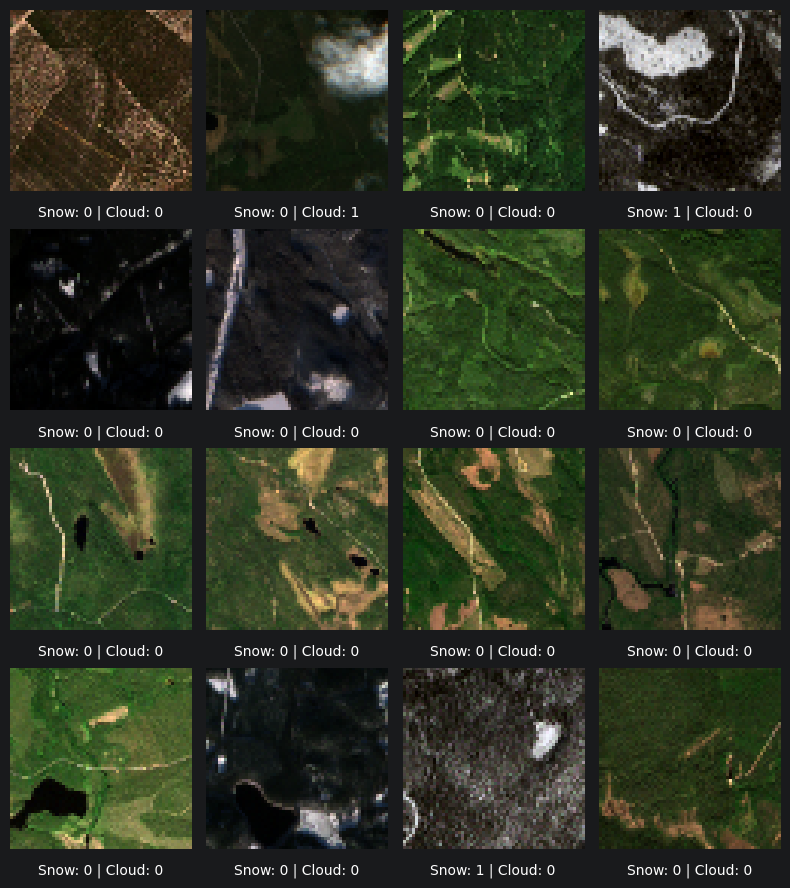

LABEL:  3


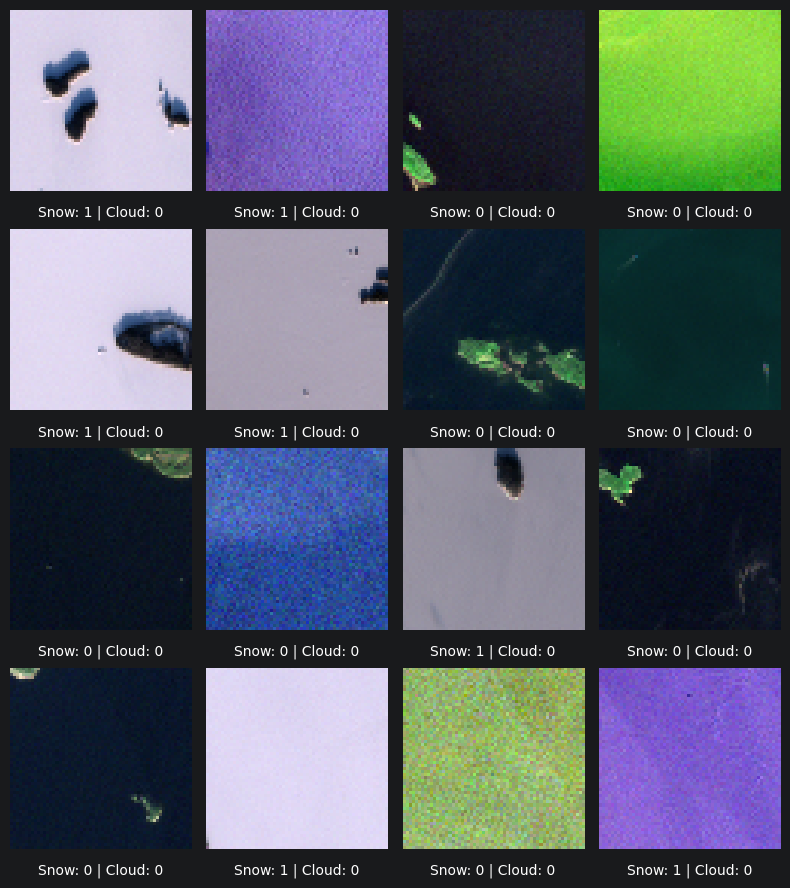

LABEL:  4


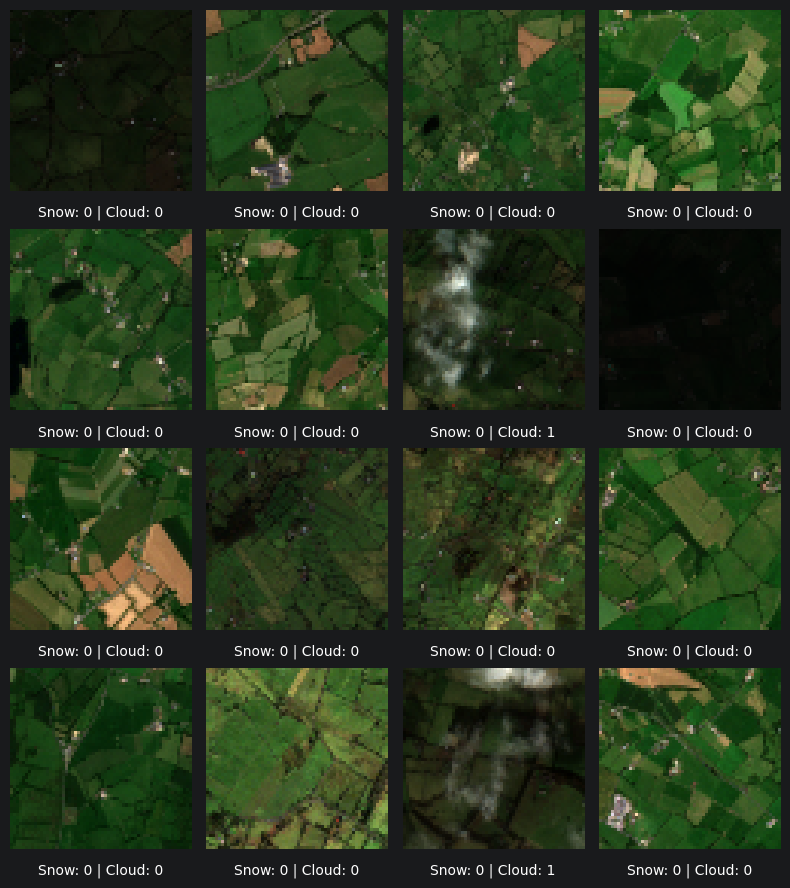

LABEL:  5


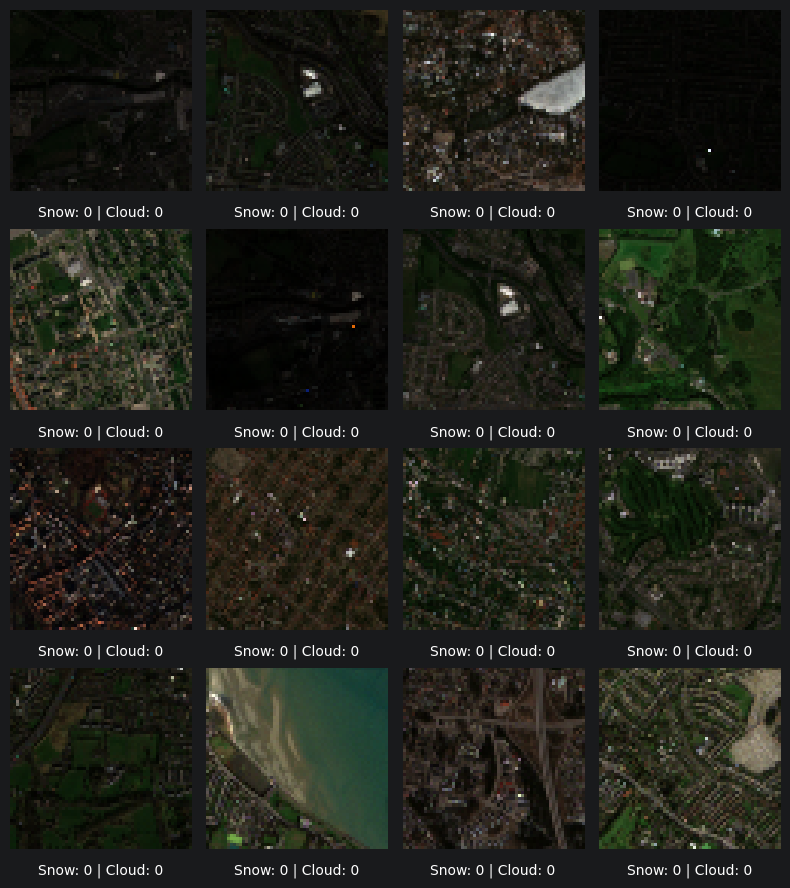

In [4]:
for label in range(6):
    print("LABEL: ", label)
    idxs = np.where(y_train == label)[0][:16]
    imgs = x_train[idxs]
    fig, axes = plt.subplots(4, 4, figsize=(8, 9))
    for i, (ax, img) in enumerate(zip(axes.flat, imgs)):
        ax.imshow(img)
        ax.axis("off")
        ax.text(0.5, -0.08, f"Snow: {y_train_is_snow[idxs[i]]} | Cloud: {y_train_is_cloud[idxs[i]]}", transform=ax.transAxes,
            ha="center", va="top", fontsize=10)
    plt.tight_layout()
    plt.show()